# Step 4 – Model Training, Evaluation and Comparison
**Code used:** this notebook (training loop) + `pathsnap/metrics.py` (metrics). Features come from notebook 02.
**Task framing:** every (GPS point, candidate road segment) pair is one row.
Target = 1 if the candidate is the point's reference arc, else 0 (binary classification).
At prediction time we pick, for each GPS point, the candidate with the highest probability.

**Partitions:** models are fitted and cross-validated on `train` (80 trips) with **GroupKFold by
trip**, so no trip appears in both a training fold and its validation fold. `student_test`
(10 trips) is used only for development-stage comparison. Only valid points (≤ 50 m from the
reference route) are scored.

In [1]:
import os, sys, time, json, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathsnap.data_loading import load_trip, list_trips
from pathsnap.feature_engineering import FEATURES
from pathsnap.metrics import candidate_metrics, observation_top1, top1_per_point, route_continuity
SEED = 42; rng = np.random.default_rng(SEED)
OUT = os.path.abspath('../results/03_models'); os.makedirs(OUT, exist_ok=True)
os.makedirs('../models', exist_ok=True)
cands = pd.read_csv('../results/02_preprocessing/features/candidates_r50_k10.csv.gz', dtype={'trip_id': str})
print(cands.shape, 'features:', FEATURES)

(1360338, 18) features: ['dist', 'dist_rank', 'dist_minus_min', 'dist_ratio', 'n_cand', 'heading_diff', 'speed', 'arc_len', 't_along', 'dist_prev', 'dist_next', 'gap']


### Training sample
Trip sizes vary a lot (361 to 19,313 GPS points). To stop one long trip dominating, and to keep
training time practical, we sample at most 1,500 GPS points per training trip (all candidates of a
sampled point are kept, so the per-point choice stays intact). Student-test is used in full.

In [2]:
tr_all = cands[(cands.partition=='train') & (cands.valid==1)]
keep = []
for tid, g in tr_all.groupby('trip_id'):
    pts = g.point_idx.unique()
    if len(pts) > 1500: pts = rng.choice(pts, 1500, replace=False)
    keep.append(g[g.point_idx.isin(pts)])
train = pd.concat(keep, ignore_index=True)
test = cands[(cands.partition=='student_test') & (cands.valid==1)].reset_index(drop=True)
X, y, groups = train[FEATURES].values, train.label.values, train.trip_id.values
Xt, yt = test[FEATURES].values, test.label.values
# number of valid GPS points (denominator for observation Top-1), incl. points with no candidates
import pickle
n_valid_train_pts = train.groupby('trip_id').point_idx.nunique().sum()
from pathsnap.feature_engineering import build_training_table
print('train rows %d (%d trips, %d points), positive share %.1f%%' % (len(train), train.trip_id.nunique(), n_valid_train_pts, 100*y.mean()))
print('student_test rows %d' % len(test))

train rows 686432 (80 trips, 97238 points), positive share 14.0%
student_test rows 131570


In [3]:
# exact count of valid student-test points (some may have no candidate at all)
valid_test_pts = {}
for tid in list_trips('student_test'):
    _, info = build_training_table(load_trip('student_test', tid))
    valid_test_pts[tid] = int(info['valid'].sum())
N_TEST_VALID = sum(valid_test_pts.values())
arcs_by_trip = {tid: load_trip('student_test', tid)['arcs'].values for tid in list_trips('student_test')}
print('valid student-test GPS points:', N_TEST_VALID)

valid student-test GPS points: 19133


### The models (7 models, 6 algorithm families)
| Model | Family | Why try it |
|---|---|---|
| Logistic Regression | Linear / probabilistic | Simple, well-calibrated probabilities, good for the HMM |
| Gaussian Naive Bayes | Probabilistic | Very fast; tests whether features can be treated as independent |
| KNN (k=25, distance-weighted) | Instance-based | No assumptions about the decision shape; needs scaling |
| Decision Tree | Tree-based | Learns rules such as "close AND same direction" |
| Random Forest | Ensemble (bagging) | Reduces the variance of a single tree |
| HistGradientBoosting | Boosting | Usually strongest on tabular data; fast on large data |
| MLP (64-32) | Neural network | Smooth non-linear boundary |

KNN and MLP are fitted on a 80k-row subsample because their cost grows quickly with data size.

In [4]:
MODELS = {
 'LogisticRegression': (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=1.0)), None),
 'GaussianNB':         (lambda: GaussianNB(), None),
 'KNN_k25':            (lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights='distance', n_jobs=-1)), 80_000),
 'DecisionTree':       (lambda: DecisionTreeClassifier(max_depth=12, min_samples_leaf=50, random_state=SEED), None),
 'RandomForest':       (lambda: RandomForestClassifier(n_estimators=100, max_depth=16, min_samples_leaf=20, n_jobs=-1, random_state=SEED), None),
 'HistGradientBoosting':(lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=31, random_state=SEED), None),
 'MLP_64_32':          (lambda: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,32), max_iter=60, early_stopping=True, random_state=SEED)), 80_000),
}
CONFIG = {'LogisticRegression':'C=1.0, L2, scaled', 'GaussianNB':'default var_smoothing',
          'KNN_k25':'k=25, distance-weighted, scaled, 80k rows', 'DecisionTree':'max_depth=12, min_leaf=50',
          'RandomForest':'100 trees, depth 16, min_leaf=20', 'HistGradientBoosting':'300 iters, lr 0.1, 31 leaves',
          'MLP_64_32':'2 hidden layers (64,32), ReLU, Adam, early stop, 80k rows'}

def subsample_idx(idx, cap):
    if cap is None or len(idx) <= cap: return idx
    return np.sort(rng.choice(idx, cap, replace=False))

gkf = GroupKFold(n_splits=5)
cv_rows, test_rows, fitted = [], [], {}
for name, (make, cap) in MODELS.items():
    fold_f1, fold_top1, fold_ll = [], [], []
    for k, (tri, vai) in enumerate(gkf.split(X, y, groups)):
        tri = subsample_idx(tri, cap)
        m = make().fit(X[tri], y[tri])
        p = m.predict_proba(X[vai])[:, 1]
        cm = candidate_metrics(y[vai], p)
        v = train.iloc[vai].assign(score=p)
        fold_f1.append(cm['macro_f1']); fold_ll.append(cm['log_loss'])
        fold_top1.append(observation_top1(v, v.groupby('trip_id').point_idx.nunique().sum()))
        cv_rows.append(dict(model=name, fold=k, cv_macro_f1=cm['macro_f1'], cv_log_loss=cm['log_loss'], cv_top1=fold_top1[-1]))
    # refit on all training rows, evaluate on student_test
    idx = subsample_idx(np.arange(len(X)), cap)
    t0 = time.time(); m = make().fit(X[idx], y[idx]); fit_time = time.time() - t0
    t0 = time.time(); p = m.predict_proba(Xt)[:, 1]; inf_time = time.time() - t0
    cm = candidate_metrics(yt, p)
    te = test.assign(score=p)
    top = top1_per_point(te)
    cont = np.nanmean([route_continuity(g.sort_values('point_idx').arc_id.values, arcs_by_trip[tid]) for tid, g in top.groupby('trip_id')])
    test_rows.append(dict(model=name, config=CONFIG[name],
        cv_macro_f1=np.mean(fold_f1), cv_macro_f1_std=np.std(fold_f1), cv_top1=np.mean(fold_top1), cv_log_loss=np.mean(fold_ll),
        test_top1=observation_top1(te, N_TEST_VALID), test_macro_f1=cm['macro_f1'], test_precision=cm['precision'],
        test_recall=cm['recall'], test_log_loss=cm['log_loss'], route_continuity=cont,
        fit_time_s=fit_time, inference_time_s=inf_time, inference_ms_per_1k_rows=1000*inf_time/len(Xt)*1000))
    fitted[name] = m; joblib.dump(m, f'../models/{name}.joblib')
    test.loc[:, f'p_{name}'] = p
    print(f"{name:22s} CV F1 {np.mean(fold_f1):.4f}±{np.std(fold_f1):.4f} | test Top-1 {test_rows[-1]['test_top1']:.4f} "
          f"| test F1 {cm['macro_f1']:.4f} | logloss {cm['log_loss']:.4f} | cont {cont:.3f} | fit {fit_time:.1f}s")
cv_df = pd.DataFrame(cv_rows); res = pd.DataFrame(test_rows)
cv_df.to_csv(f'{OUT}/cv_folds.csv', index=False); res.to_csv(f'{OUT}/model_comparison.csv', index=False)
test[['trip_id','point_idx','arc_id','label']+[c for c in test.columns if c.startswith('p_')]].to_csv(f'{OUT}/student_test_predictions.csv.gz', index=False)

LogisticRegression     CV F1 0.9004±0.0124 | test Top-1 0.8611 | test F1 0.9036 | logloss 0.1363 | cont 0.923 | fit 2.0s


GaussianNB             CV F1 0.7818±0.0057 | test Top-1 0.8355 | test F1 0.7756 | logloss 0.7548 | cont 0.908 | fit 0.3s


KNN_k25                CV F1 0.9088±0.0116 | test Top-1 0.8610 | test F1 0.9130 | logloss 0.1382 | cont 0.926 | fit 0.1s


DecisionTree           CV F1 0.9212±0.0122 | test Top-1 0.8711 | test F1 0.9197 | logloss 0.1055 | cont 0.930 | fit 7.7s


RandomForest           CV F1 0.9249±0.0129 | test Top-1 0.8739 | test F1 0.9232 | logloss 0.0907 | cont 0.931 | fit 27.7s


HistGradientBoosting   CV F1 0.9250±0.0120 | test Top-1 0.8721 | test F1 0.9226 | logloss 0.0942 | cont 0.930 | fit 3.0s


MLP_64_32              CV F1 0.9155±0.0123 | test Top-1 0.8669 | test F1 0.9161 | logloss 0.1019 | cont 0.933 | fit 4.0s


### 3.1 Overall model comparison (format of the Deliverables PDF)

In [5]:
FAMILY = {'LogisticRegression':'Linear / probabilistic', 'GaussianNB':'Probabilistic', 'KNN_k25':'Instance-based',
          'DecisionTree':'Tree-based', 'RandomForest':'Ensemble (bagging)', 'HistGradientBoosting':'Boosting', 'MLP_64_32':'Neural network'}
table = pd.DataFrame({'Model': res.model, 'Algorithm family': res.model.map(FAMILY), 'Key configuration': res.config,
    'CV Macro F1-score': res.cv_macro_f1.round(4), 'Top-1 accuracy (student-test)': res.test_top1.round(4),
    'Route continuity': res.route_continuity.round(4), 'Student-test Macro F1-score': res.test_macro_f1.round(4),
    'Log loss': res.test_log_loss.round(4), 'Inference time (s, all student-test rows)': res.inference_time_s.round(3)})
table = table.sort_values('Top-1 accuracy (student-test)', ascending=False)
table.to_csv(f'{OUT}/consolidated_comparison_table.csv', index=False); table

,Model,Algorithm family,Key configuration,CV Macro F1-score,Top-1 accuracy (student-test),Route continuity,Student-test Macro F1-score,Log loss,"Inference time (s, all student-test rows)"
4,RandomForest,Ensemble (bagging),"100 trees, depth 16, min_leaf=20",0.9249,0.8739,0.9309,0.9232,0.0907,0.172
5,HistGradientBoosting,Boosting,"300 iters, lr 0.1, 31 leaves",0.9250,0.8721,0.9300,0.9226,0.0942,0.123
3,DecisionTree,Tree-based,"max_depth=12, min_leaf=50",0.9212,0.8711,0.9302,0.9197,0.1055,0.012
6,MLP_64_32,Neural network,"2 hidden layers (64,32), ReLU, Adam, early sto...",0.9155,0.8669,0.9334,0.9161,0.1019,0.058
0,LogisticRegression,Linear / probabilistic,"C=1.0, L2, scaled",0.9004,0.8611,0.9227,0.9036,0.1363,0.021
2,KNN_k25,Instance-based,"k=25, distance-weighted, scaled, 80k rows",0.9088,0.8610,0.9258,0.9130,0.1382,23.989
1,GaussianNB,Probabilistic,default var_smoothing,0.7818,0.8355,0.9078,0.7756,0.7548,0.070


### Detailed comparison

In [6]:
base = pd.read_csv('../results/02_preprocessing/baseline_nearest.csv')
nearest = base[base.partition=='student_test'].top1_accuracy.iloc[0]
show = res[['model','config','cv_macro_f1','cv_macro_f1_std','test_top1','route_continuity','test_macro_f1','test_log_loss','inference_time_s']].copy()
show.round(4).sort_values('test_top1', ascending=False)

,model,config,cv_macro_f1,cv_macro_f1_std,test_top1,route_continuity,test_macro_f1,test_log_loss,inference_time_s
4,RandomForest,"100 trees, depth 16, min_leaf=20",0.9249,0.0129,0.8739,0.9309,0.9232,0.0907,0.1724
5,HistGradientBoosting,"300 iters, lr 0.1, 31 leaves",0.9250,0.0120,0.8721,0.9300,0.9226,0.0942,0.1233
3,DecisionTree,"max_depth=12, min_leaf=50",0.9212,0.0122,0.8711,0.9302,0.9197,0.1055,0.0116
6,MLP_64_32,"2 hidden layers (64,32), ReLU, Adam, early sto...",0.9155,0.0123,0.8669,0.9334,0.9161,0.1019,0.0575
0,LogisticRegression,"C=1.0, L2, scaled",0.9004,0.0124,0.8611,0.9227,0.9036,0.1363,0.0213
2,KNN_k25,"k=25, distance-weighted, scaled, 80k rows",0.9088,0.0116,0.8610,0.9258,0.9130,0.1382,23.9887
1,GaussianNB,default var_smoothing,0.7818,0.0057,0.8355,0.9078,0.7756,0.7548,0.0700


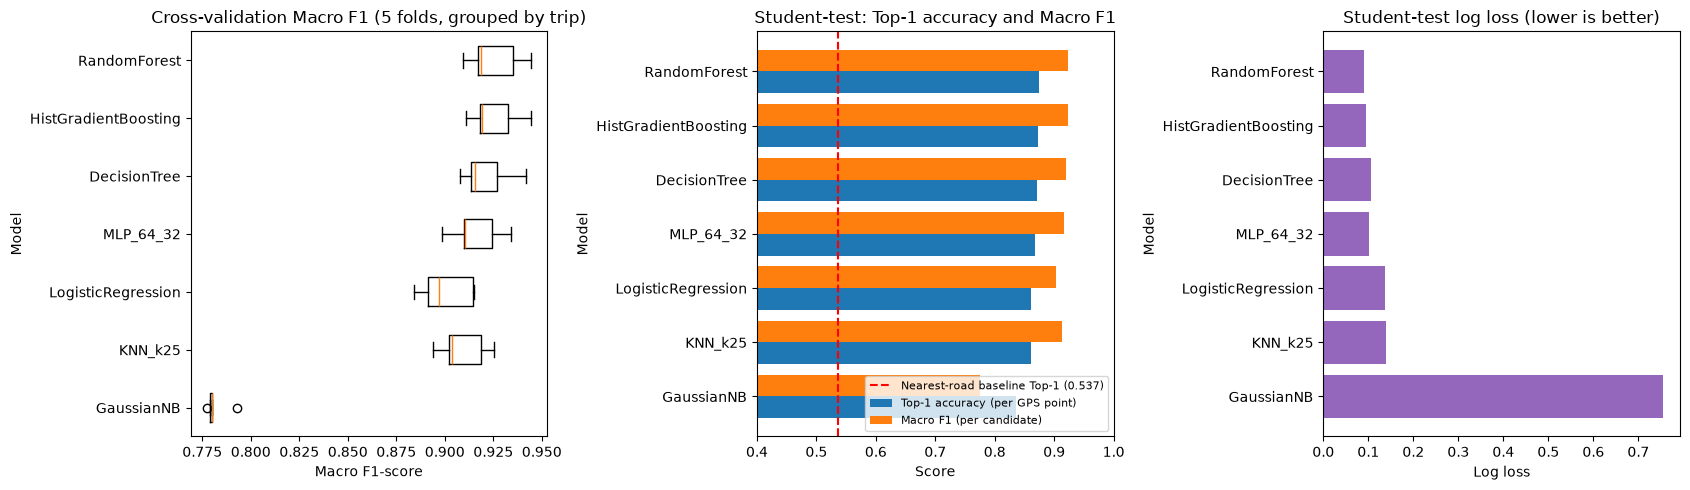

In [7]:
order = res.sort_values('test_top1').model
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
b = cv_df.pivot(index='fold', columns='model', values='cv_macro_f1')[order]
ax[0].boxplot(b.values, tick_labels=order, orientation='horizontal'); ax[0].set_title('Cross-validation Macro F1 (5 folds, grouped by trip)')
ax[0].set_xlabel('Macro F1-score'); ax[0].set_ylabel('Model')
r = res.set_index('model').loc[order]; yy = np.arange(len(order))
ax[1].barh(yy-0.2, r.test_top1, 0.4, color='tab:blue', label='Top-1 accuracy (per GPS point)')
ax[1].barh(yy+0.2, r.test_macro_f1, 0.4, color='tab:orange', label='Macro F1 (per candidate)')
ax[1].axvline(nearest, color='red', ls='--', label=f'Nearest-road baseline Top-1 ({nearest:.3f})')
ax[1].set_yticks(yy); ax[1].set_yticklabels(order); ax[1].set_xlim(0.4, 1.0)
ax[1].set_title('Student-test: Top-1 accuracy and Macro F1'); ax[1].set_xlabel('Score'); ax[1].set_ylabel('Model'); ax[1].legend(loc='lower right', fontsize=8)
ax[2].barh(yy, r.test_log_loss, color='tab:purple'); ax[2].set_yticks(yy); ax[2].set_yticklabels(order)
ax[2].set_title('Student-test log loss (lower is better)'); ax[2].set_xlabel('Log loss'); ax[2].set_ylabel('Model')
plt.tight_layout(); plt.savefig(f'{OUT}/model_comparison.png'); plt.show()

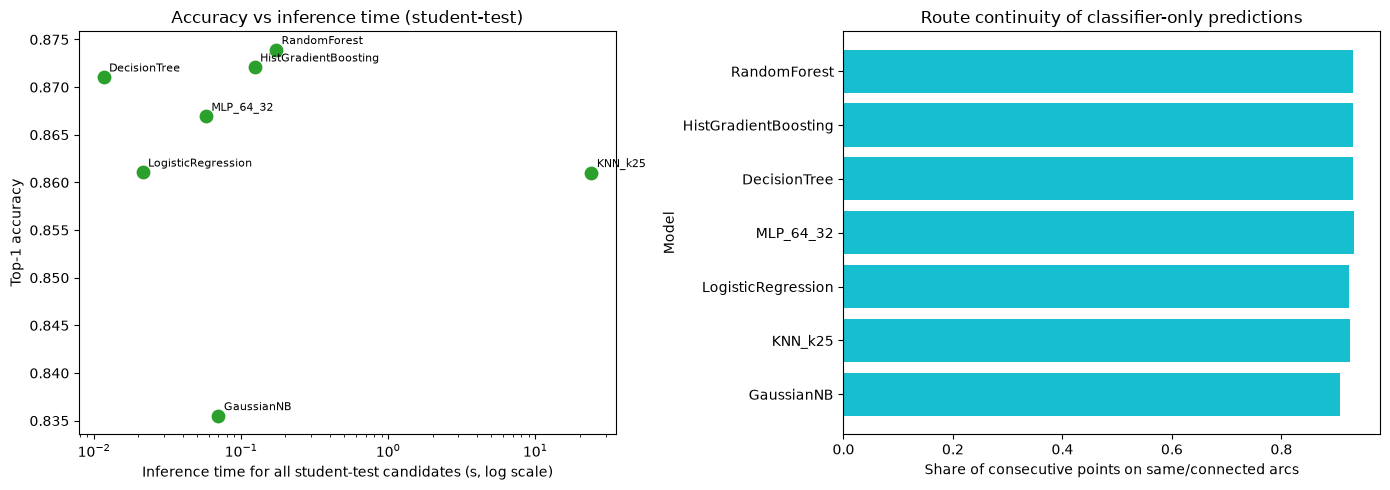

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(res.inference_time_s, res.test_top1, s=80, color='tab:green')
for _, r in res.iterrows(): ax[0].annotate(r.model, (r.inference_time_s, r.test_top1), fontsize=8, xytext=(4,4), textcoords='offset points')
ax[0].set_xscale('log'); ax[0].set_title('Accuracy vs inference time (student-test)')
ax[0].set_xlabel('Inference time for all student-test candidates (s, log scale)'); ax[0].set_ylabel('Top-1 accuracy')
ax[1].barh(order, res.set_index('model').loc[order].route_continuity, color='tab:cyan')
ax[1].set_title('Route continuity of classifier-only predictions'); ax[1].set_xlabel('Share of consecutive points on same/connected arcs'); ax[1].set_ylabel('Model')
plt.tight_layout(); plt.savefig(f'{OUT}/speed_and_continuity.png'); plt.show()

### Over/under-fitting check: train-fold vs validation-fold score

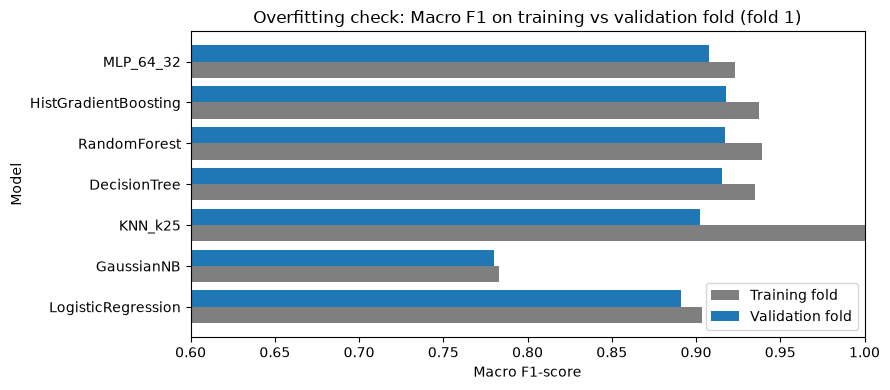

,model,train_f1,val_f1,gap
0,LogisticRegression,0.9037,0.8912,0.0125
1,GaussianNB,0.7833,0.7800,0.0033
2,KNN_k25,1.0000,0.9021,0.0979
3,DecisionTree,0.9350,0.9156,0.0194
4,RandomForest,0.9393,0.9169,0.0223
5,HistGradientBoosting,0.9375,0.9180,0.0195
6,MLP_64_32,0.9230,0.9078,0.0152


In [9]:
rows = []
for name, (make, cap) in MODELS.items():
    tri, vai = next(gkf.split(X, y, groups)); tri = subsample_idx(tri, cap)
    m = make().fit(X[tri], y[tri])
    rows.append(dict(model=name, train_f1=candidate_metrics(y[tri], m.predict_proba(X[tri])[:,1])['macro_f1'],
                     val_f1=candidate_metrics(y[vai], m.predict_proba(X[vai])[:,1])['macro_f1']))
fit_gap = pd.DataFrame(rows); fit_gap['gap'] = fit_gap.train_f1 - fit_gap.val_f1
fit_gap.to_csv(f'{OUT}/train_vs_val_gap.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4)); yy = np.arange(len(fit_gap))
ax.barh(yy-0.2, fit_gap.train_f1, 0.4, label='Training fold', color='tab:gray')
ax.barh(yy+0.2, fit_gap.val_f1, 0.4, label='Validation fold', color='tab:blue')
ax.set_yticks(yy); ax.set_yticklabels(fit_gap.model); ax.set_xlim(0.6, 1.0)
ax.set_title('Overfitting check: Macro F1 on training vs validation fold (fold 1)'); ax.set_xlabel('Macro F1-score'); ax.set_ylabel('Model'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/overfit_check.png'); plt.show(); fit_gap.round(4)

### MLP training history (the only model here with epoch-wise curves)

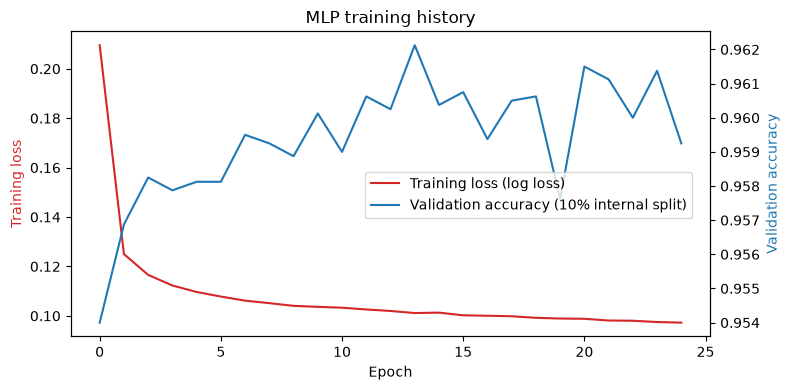

In [10]:
mlp = fitted['MLP_64_32'][-1]
fig, ax1 = plt.subplots(figsize=(8,4)); ax2 = ax1.twinx()
ax1.plot(mlp.loss_curve_, color='tab:red', label='Training loss (log loss)')
ax2.plot(mlp.validation_scores_, color='tab:blue', label='Validation accuracy (10% internal split)')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Training loss', color='tab:red'); ax2.set_ylabel('Validation accuracy', color='tab:blue')
ax1.set_title('MLP training history'); fig.legend(loc='center right', bbox_to_anchor=(0.88, 0.5)); plt.tight_layout()
plt.savefig(f'{OUT}/mlp_training_curve.png'); plt.show()

### Confusion matrices (student-test, candidate level, threshold 0.5)

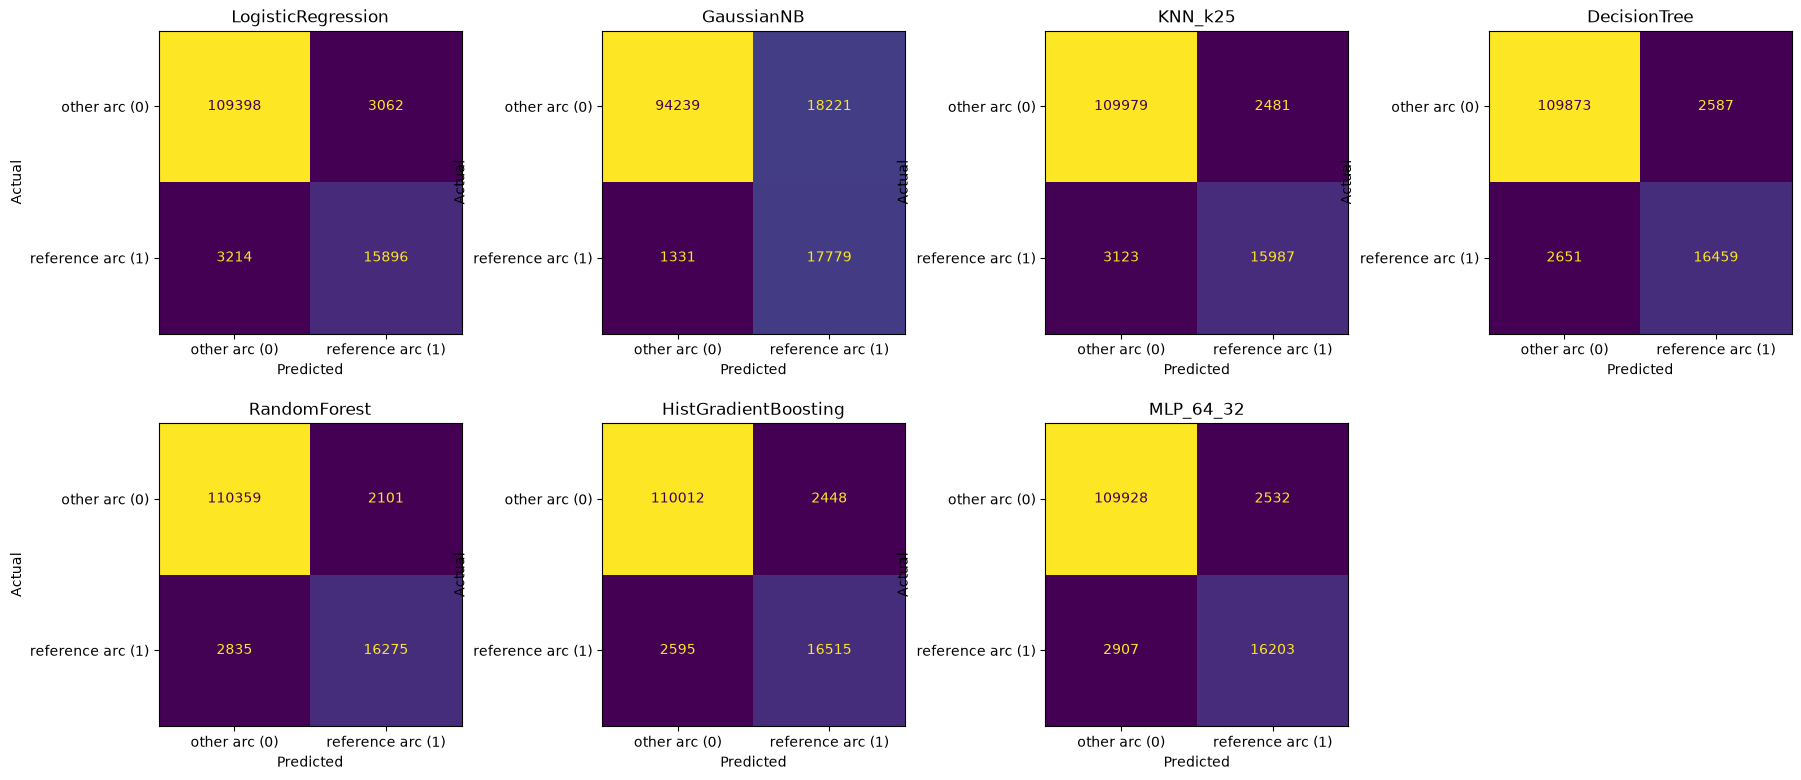

In [11]:
fig, ax = plt.subplots(2, 4, figsize=(18, 8)); ax = ax.ravel()
for k, name in enumerate(MODELS):
    cmx = confusion_matrix(yt, (test[f'p_{name}'] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cmx, display_labels=['other arc (0)','reference arc (1)']).plot(ax=ax[k], colorbar=False, values_format='d')
    ax[k].set_title(name); ax[k].set_xlabel('Predicted'); ax[k].set_ylabel('Actual')
ax[-1].axis('off'); plt.tight_layout(); plt.savefig(f'{OUT}/confusion_matrices.png'); plt.show()

### Feature importance (HistGradientBoosting, permutation on student-test sample)

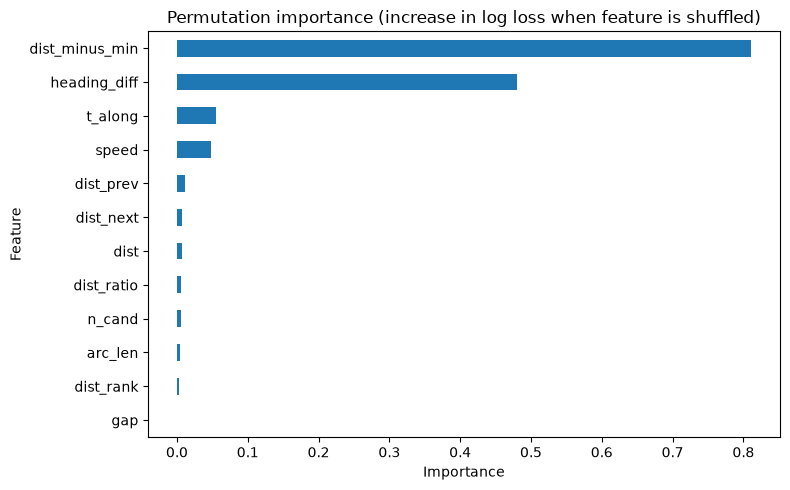

In [12]:
from sklearn.inspection import permutation_importance
s = rng.choice(len(Xt), min(40000, len(Xt)), replace=False)
pi = permutation_importance(fitted['HistGradientBoosting'], Xt[s], yt[s], n_repeats=3, random_state=SEED, scoring='neg_log_loss')
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8,5)); imp.plot.barh(ax=ax, color='tab:blue')
ax.set_title('Permutation importance (increase in log loss when feature is shuffled)'); ax.set_xlabel('Importance'); ax.set_ylabel('Feature')
plt.tight_layout(); plt.savefig(f'{OUT}/feature_importance.png'); plt.show()